In [27]:
import numpy as np
import pandas as pd
import mne
import h5py
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nilearn.plotting import plot_markers
from mne_bids import BIDSPath

from himalaya.backend import set_backend, get_backend
from himalaya.ridge import RidgeCV
from himalaya.scoring import correlation_score

from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import re
import mne
import numpy as np
from mne_bids import BIDSPath
from nilearn import datasets, image
from scipy.spatial import KDTree
from collections import Counter

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import fdrcorrection
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
from transformers import GPT2Tokenizer
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mne_bids import BIDSPath
from scipy.signal import convolve
from scipy.stats import zscore

import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, zscore
from scipy.signal import convolve
from mne_bids import BIDSPath

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.signal import convolve
from mne_bids import BIDSPath
import pingouin as pg  # The partial correlation library


In [6]:
transcript_path = "stimuli/podcast_transcript.csv"

df = pd.read_csv(transcript_path)
df.head(20)

,word,start,end
0,Act,3.710,3.790
1,"one,",3.990,4.190
2,monkey,4.651,4.931
3,in,4.951,5.011
4,the,5.051,5.111
5,middle.,5.151,5.391
6,So,6.592,6.732
7,there's,6.752,6.912
8,some,6.892,7.052
9,places,7.072,7.342


In [7]:
glove_path = 'glove.6B.50d.txt'
#create the glove model based on our glove file in google drive
def load_glove_to_dict(file_path):
    glove_dict = {}
    print(f"Loading {file_path}...")

    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            # Each line looks like: word 0.123 0.456 ...
            values = line.split()
            word = values[0]
            # Convert the numbers into a numpy array
            vector = np.asarray(values[1:], dtype='float32')
            glove_dict[word] = vector

    print(f"Done! {len(glove_dict)} words loaded.")
    return glove_dict


# 3. Load the model (this will take a few seconds)
glove_model = load_glove_to_dict(glove_path)

# ── Build GloVe embeddings for the transcript ──────────────────────────────

def clean_word(w):
    """Better clean up: Lowercase + normalize apostrophes + strip punctuation."""
    w = str(w).lower()
    # Normalize curly apostrophes to straight ones for GloVe compatibility
    w = re.sub(r"[’‘’ʻ]", "'", w)
    # Strip punctuation but keep internal apostrophes (don't strip ')
    return w.strip(" .,!?;:\"()-[]")

# Update the dataframe with the better cleanup
df["word_clean"] = df["word"].apply(clean_word)

# Define words that should be excluded as fillers (matching the paper)
EXCLUDE_FILLERS = {'ch', 'hm', 'mhm', 'mm','uh', 'um'}

# ── Assign embeddings, track OOV words ─────────────────────────────────────
def get_glove_vector(w):
    if w in EXCLUDE_FILLERS or w not in glove_model:
        return None
    return glove_model[w]

# Apply the function to create a new column
df["glove_embedding"] = df["word_clean"].apply(get_glove_vector)

# 4. Filter the dataframe to remove rows where no embedding was found (None)
# This replaces your 'word_indices' and 'embeddings_list' logic
df_glove = df.dropna(subset=["glove_embedding"]).copy()

# 5. Optional: Create your X_glove matrix for the encoding model
# This stacks the arrays from the column into a single numpy matrix
X_glove = np.stack(df_glove["glove_embedding"].values).astype("float32")

# 6. Track OOV for your report
oov_count = len(df) - len(df_glove)

print("=" * 50)
print(f"Total words in transcript : {len(df)}")
print(f"Words WITH GloVe embedding: {len(df_glove)}")
print(f"Words WITHOUT (OOV/Fill)  : {oov_count}")
print(f"X_glove shape             : {X_glove.shape}")
print("=" * 50)

# Show the first few rows - you'll see the embedding array in the new column
df_glove.head(8)

Loading glove.6B.50d.txt...
Done! 400000 words loaded.
Total words in transcript : 5136
Words WITH GloVe embedding: 4867
Words WITHOUT (OOV/Fill)  : 269
X_glove shape             : (4867, 50)


,word,start,end,word_clean,glove_embedding
0,Act,3.710,3.790,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,"one,",3.990,4.190,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,monkey,4.651,4.931,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."
3,in,4.951,5.011,in,"[0.33042, 0.24995, -0.60874, 0.10923, 0.036372..."
4,the,5.051,5.111,the,"[0.418, 0.24968, -0.41242, 0.1217, 0.34527, -0..."
5,middle.,5.151,5.391,middle,"[-0.15502, 1.0436, -0.22143, -0.89604, 0.49455..."
6,So,6.592,6.732,so,"[0.60308, -0.32024, 0.088857, -0.55176, 0.5318..."
8,some,6.892,7.052,some,"[0.92871, -0.10834, 0.21497, -0.50237, 0.10379..."


In [8]:
transcript_path = "stimuli/gpt2-xl/transcript.tsv"
df_gpt = pd.read_csv(transcript_path, sep="\t", index_col=0)


In [9]:
#turning tokens into words, if word is more than one token, keeping the first tokens ranks (since that the first thing gpt is predicting anyways)
#also keeping the first tokens true_probability, entropy, top_prediction, ect.
#if top prediction is a half-word and that not avaliable in vocbulary is it excluded
df_gpt = (df_gpt
          .groupby('word_idx', sort=True)
          .first()
          .reset_index())

In [10]:

# 3. Apply cleaning to the GPT dataframe (which you already grouped by word_idx)
df_gpt["word_clean"] = df_gpt["word"].apply(clean_word)

# 4. Filter and assign GloVe embeddings
# This creates the additional column and filters rows in one pass
embeddings = []
valid_indices = []

for idx, row in df_gpt.iterrows():
    w = row["word_clean"]
    # Keep only if NOT a filler AND exists in GloVe vocabulary
    if w not in EXCLUDE_FILLERS and w in glove_model:
        embeddings.append(glove_model[w])
        valid_indices.append(idx)

# 5. Create the final filtered dataframe with all original GPT columns + embeddings
df_gpt_glove = df_gpt.loc[valid_indices].copy()
df_gpt_glove["glove_embedding"] = embeddings

# ── Verification ──────────────────────────────────────────────────────────
print(f"Original GPT words: {len(df_gpt)}")
print(f"Final aligned rows: {len(df_gpt_glove)}")
# The paper reports 4,843 words for the full GloVe analysis

Original GPT words: 5136
Final aligned rows: 4867


In [11]:
df_glove.shape

(4867, 5)

In [12]:
df_gpt_glove.shape

(4867, 12)

In [13]:
df_gpt_glove

,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,word_clean,glove_embedding
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."
3,3,in,4.951,5.011,Ġin,287,15,0.004237,0,4.444838,in,"[0.33042, 0.24995, -0.60874, 0.10923, 0.036372..."
4,4,the,5.051,5.111,Ġthe,262,0,0.392205,262,3.781622,the,"[0.418, 0.24968, -0.41242, 0.1217, 0.34527, -0..."
...,...,...,...,...,...,...,...,...,...,...,...,...
5131,5131,go,1798.546,1798.646,Ġgo,467,20,0.008662,651,5.197536,go,"[0.14828, 0.17761, 0.42346, -0.31489, 0.32273,..."
5132,5132,to,1798.666,1798.746,Ġto,284,0,0.202626,284,3.946364,to,"[0.68047, -0.039263, 0.30186, -0.17792, 0.4296..."
5133,5133,court,1798.786,1799.006,Ġcourt,2184,99,0.000510,257,3.669363,court,"[-0.35445, -0.55181, -1.024, 0.59384, 0.57911,..."
5134,5134,over,1799.046,1799.226,Ġover,625,4,0.062957,284,3.113599,over,"[0.12972, 0.088073, 0.24375, 0.078102, -0.1278..."


In [14]:
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)
print("Subjects in CSV:", sig_elec_master["subject"].unique())
print("CSV columns:", sig_elec_master.columns.tolist())

Subjects in CSV: <StringArray>
['03', '04', '05', '06', '07', '08', '09']
Length: 7, dtype: str
CSV columns: ['subject', 'ch_name', 'x_mni', 'y_mni', 'z_mni', 'elec_idx']


In [15]:
sig_elec_master

,subject,ch_name,x_mni,y_mni,z_mni,elec_idx
0,03,LGA4,-59.000000,22.666667,34.666669,2
1,03,LGA7,-61.999999,-7.000000,48.000000,5
2,03,LGA10,-59.000000,37.999999,13.000000,8
3,03,LGA11,-62.399998,28.800000,18.800000,9
4,03,LGA19,-64.800002,24.800001,8.400000,17
...,...,...,...,...,...,...
169,09,AF6,-52.999999,46.000000,17.000001,159
170,09,IF4,-34.666669,39.999999,-23.333333,163
171,09,DAMT3,-29.600000,-11.200000,-11.200000,166
172,09,DPI2,-45.000002,-14.000000,8.000000,185


In [16]:
df_gpt_glove.head(3)

,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,word_clean,glove_embedding
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."


# Computing Correlation (R) Pearson

In [33]:
# --- 1. SETUP & FEATURE PREPARATION ---
bids_root = "/Users/iadician/Desktop/AI NEURO CODE/"

df = df_gpt_glove.copy()
df['cross_entropy'] = -np.log2(df['true_prob'].clip(lower=1e-10))

sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
tmin, tmax = -2.0, 2.0
# These are our 161 "points of interest"
lags = np.arange(-2.0, 2.0 + 0.025/2, 0.025) 

all_entropy_rs = []
all_surprise_rs = []

# --- 2. HELPER FUNCTIONS ---
def hamming_smooth(data, sfreq, window_ms=50):
    n_samples = int(window_ms / 1000 * sfreq)
    if n_samples % 2 == 0: n_samples += 1
    win = np.hamming(n_samples)
    win /= win.sum()
    smoothed = np.zeros_like(data)
    for ch in range(data.shape[0]):
        fwd = convolve(data[ch], win, mode='same')
        smoothed[ch] = convolve(fwd[::-1], win, mode='same')[::-1]
    return smoothed

def make_events(df_words, sfreq):
    events = np.zeros((len(df_words), 3), dtype=int)
    events[:, 0] = (df_words['start'].values * sfreq).astype(int)
    events[:, 2] = np.arange(len(df_words)) 
    return events

# --- 3. THE SUBJECT LOOP ---
for sid in subject_ids:
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0: continue
    
    print(f"Processing Subject {sid}...")
    
    file_path = BIDSPath(root=f"{bids_root}derivatives/ecogprep", subject=sid, 
                         task="podcast", datatype="ieeg", description="highgamma", 
                         suffix="ieeg", extension=".fif")
    
    try:
        raw = mne.io.read_raw_fif(file_path.fpath, verbose=False, preload=True)
    except: continue
    
    # Selection: LH + Significant
    ch2loc = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask = coords_mm[:, 0] < 0
    raw = raw.copy().pick([ch for ch, k in zip(raw.ch_names, lh_mask) if k])
    valid_indices = [i for i in sub_sig["elec_idx"].values if i < len(raw.ch_names)]
    raw = raw.copy().pick([raw.ch_names[i] for i in valid_indices])
    
    sfreq = raw.info['sfreq']

    # PREPROCESSING
    data = raw.get_data()
    data = np.log10(np.clip(data, 1e-10, None))
    data = zscore(data, axis=1)
    data = hamming_smooth(data, sfreq, 50)
    raw_proc = mne.io.RawArray(data, raw.info, verbose=False)
    
    # EPOCHING
    events = make_events(df, sfreq)
    epochs = mne.Epochs(raw_proc, events, tmin=tmin, tmax=tmax, 
                        baseline=None, preload=True, verbose=False, event_repeated='merge')
    
    df_filtered = df.iloc[epochs.selection]
    ent_vals = zscore(df_filtered['entropy'].values)
    surp_vals = zscore(df_filtered['cross_entropy'].values)
    
    epochs_data = epochs.get_data(copy=True) # (words, elecs, times)
    times = epochs.times
    
    # --- NO WINDOW AVERAGING ---
    # Instead of a window, we find the index of the exact lag time
    lag_indices = [np.argmin(np.abs(times - τ)) for τ in lags]
    # Pick only those specific time points
    binned_data = epochs_data[:, :, lag_indices] # Shape: (words, elecs, 161)

    # CORRELATION
    n_words, n_elecs, n_lags = binned_data.shape
    for e in range(n_elecs):
        e_ent, e_surp = [], []
        for t in range(n_lags):
            brain_vec = binned_data[:, e, t]
            r_ent, _ = pearsonr(brain_vec, ent_vals)
            r_surp, _ = pearsonr(brain_vec, surp_vals)
            e_ent.append(r_ent)
            e_surp.append(r_surp)
        all_entropy_rs.append(e_ent)
        all_surprise_rs.append(e_surp)



Processing Subject 03...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/96200428.py:70: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, events, tmin=tmin, tmax=tmax,


Processing Subject 04...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/96200428.py:70: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, events, tmin=tmin, tmax=tmax,


Processing Subject 05...


...

/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/96200428.py:70: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, events, tmin=tmin, tmax=tmax,


Processing Subject 08...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/96200428.py:70: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, events, tmin=tmin, tmax=tmax,


Processing Subject 09...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/96200428.py:70: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, events, tmin=tmin, tmax=tmax,


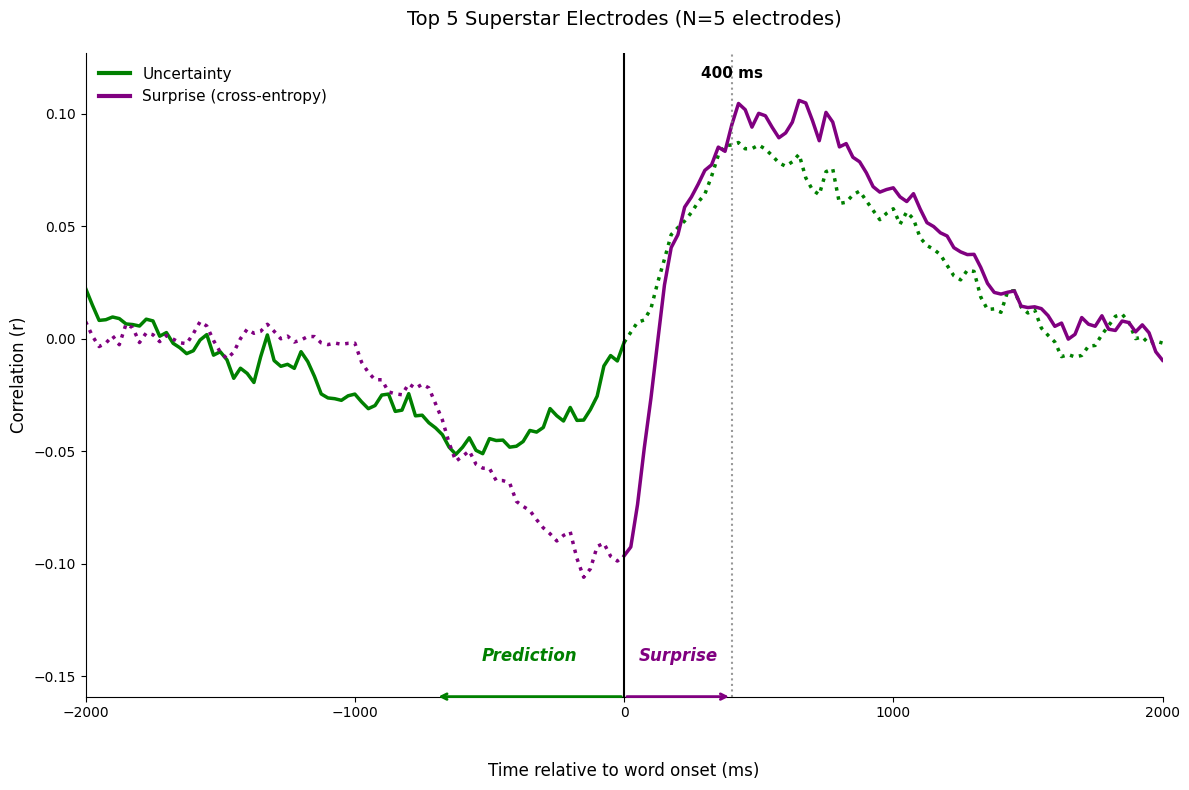

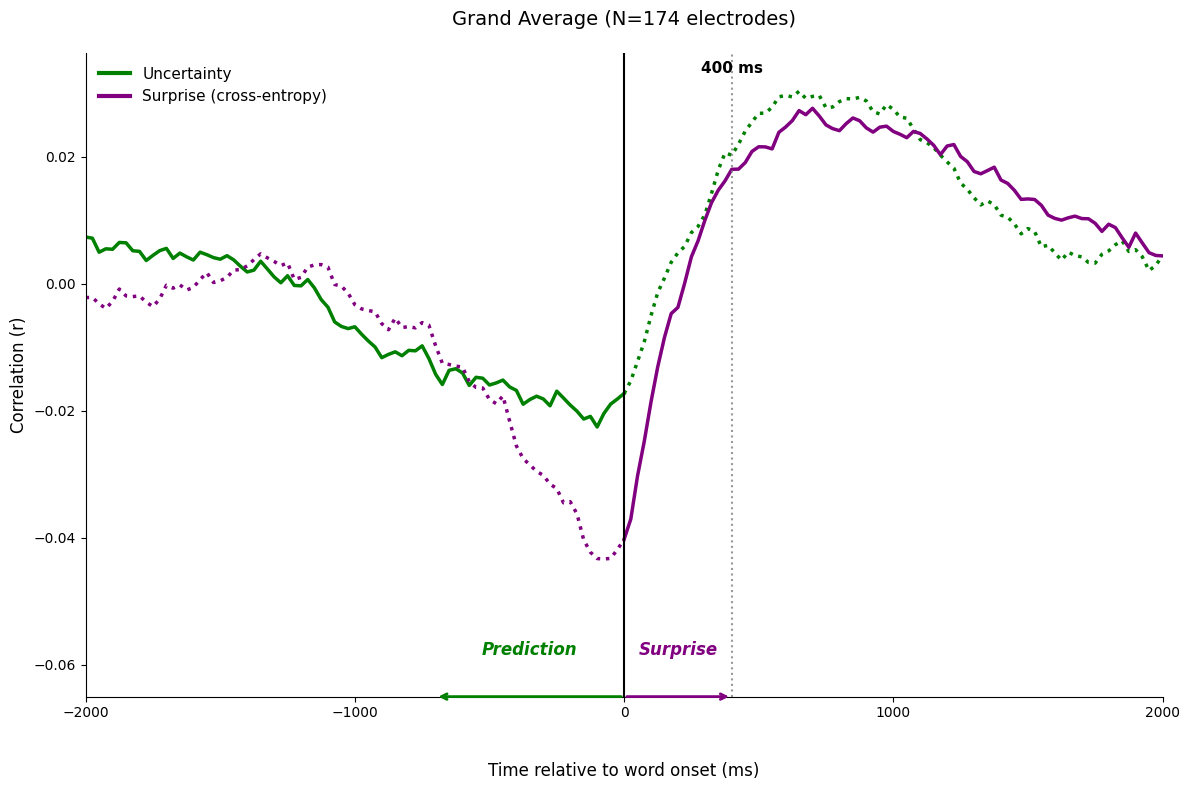

In [35]:
########### Plotting regular Correlations

ent_arr = np.array(all_entropy_rs)
surp_arr = np.array(all_surprise_rs)

# Convert lags to milliseconds
lags_ms = lags * 1000
zero_idx = np.argmin(np.abs(lags_ms))

# Identify Top 5 electrodes
peak_r_scores = np.max(np.abs(surp_arr), axis=1)
top_5_indices = np.argsort(peak_r_scores)[-5:]

# Calculate Averages
m_ent_top5 = ent_arr[top_5_indices].mean(axis=0)
m_surp_top5 = surp_arr[top_5_indices].mean(axis=0)

m_ent_all = ent_arr.mean(axis=0)
m_surp_all = surp_arr.mean(axis=0)

# Define legend handles
custom_lines = [
    Line2D([0], [0], color='green', lw=3),
    Line2D([0], [0], color='purple', lw=3)
]

def plot_publication_style_replica(ent_data, surp_data, title, n_elecs):
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # 1. Plot Curves (Solid/Dotted split)
    # Uncertainty (Green)
    ax.plot(lags_ms[:zero_idx+1], ent_data[:zero_idx+1], color='green', lw=2.5, linestyle='-', label='Uncertainty')
    ax.plot(lags_ms[zero_idx:], ent_data[zero_idx:], color='green', lw=2.5, linestyle=':')
    
    # Surprise (Purple)
    ax.plot(lags_ms[:zero_idx+1], surp_data[:zero_idx+1], color='purple', lw=2.5, linestyle=':')
    ax.plot(lags_ms[zero_idx:], surp_data[zero_idx:], color='purple', lw=2.5, linestyle='-', label='Surprise')

    # 2. Set Axis Limits & Dynamic Floor
    # We add padding at the bottom for the arrows
    data_min = min(ent_data.min(), surp_data.min())
    data_max = max(ent_data.max(), surp_data.max())
    
    y_min = data_min - (abs(data_min) * 0.5) if data_min < 0 else -0.05
    y_max = data_max + (abs(data_max) * 0.2)
    ax.set_ylim(y_min, y_max)
    ax.set_xlim(-2000, 2000)

    # 3. Vertical Markers
    ax.axvline(0, color="black", lw=1.5) # Word Onset
    ax.axvline(400, color="grey", lw=1.5, ls=":", alpha=0.8) # 400ms Marker
    
    # "400 ms" label at the top of the dotted line
    ax.text(400, y_max * 0.9, "400 ms", ha='center', va='bottom', 
            fontsize=11, color='black', fontweight='bold')

    # 4. Styling Spines (The Floor look)
    ax.spines['bottom'].set_position(('data', y_min))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # No axhline(0) as requested

    # 5. --- ARROWS ON THE FLOOR ---
    # Green Prediction Arrow (0 to -700)
    ax.annotate('', xy=(-700, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='green', lw=2))
    ax.text(-350, y_min + (abs(y_min)*0.1), "Prediction", 
            color="green", style="italic", ha="center", fontweight='bold', fontsize=12)

    # Purple Surprise Arrow (0 to 400)
    ax.annotate('', xy=(400, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='purple', lw=2))
    ax.text(200, y_min + (abs(y_min)*0.1), "Surprise", 
            color="purple", style="italic", ha="center", fontweight='bold', fontsize=12)

    # 6. Final Formatting
    ax.set_xticks([-2000, -1000, 0, 1000, 2000])
    ax.set_xlabel("Time relative to word onset (ms)", fontsize=12, labelpad=30)
    ax.set_ylabel("Correlation (r)", fontsize=12)
    ax.set_title(f"{title} (N={n_elecs} electrodes)", fontsize=14, pad=20)
    
    ax.legend(custom_lines, ['Uncertainty', 'Surprise (cross-entropy)'], 
               loc='upper left', frameon=False, fontsize=11)
    
    plt.tight_layout()
    plt.show()

# --- 5. EXECUTE PLOTS ---

# Plot Top 5
plot_publication_style_replica(m_ent_top5, m_surp_top5, "Top 5 Superstar Electrodes", 5)

# Plot Grand Average
plot_publication_style_replica(m_ent_all, m_surp_all, "Grand Average", len(all_entropy_rs))

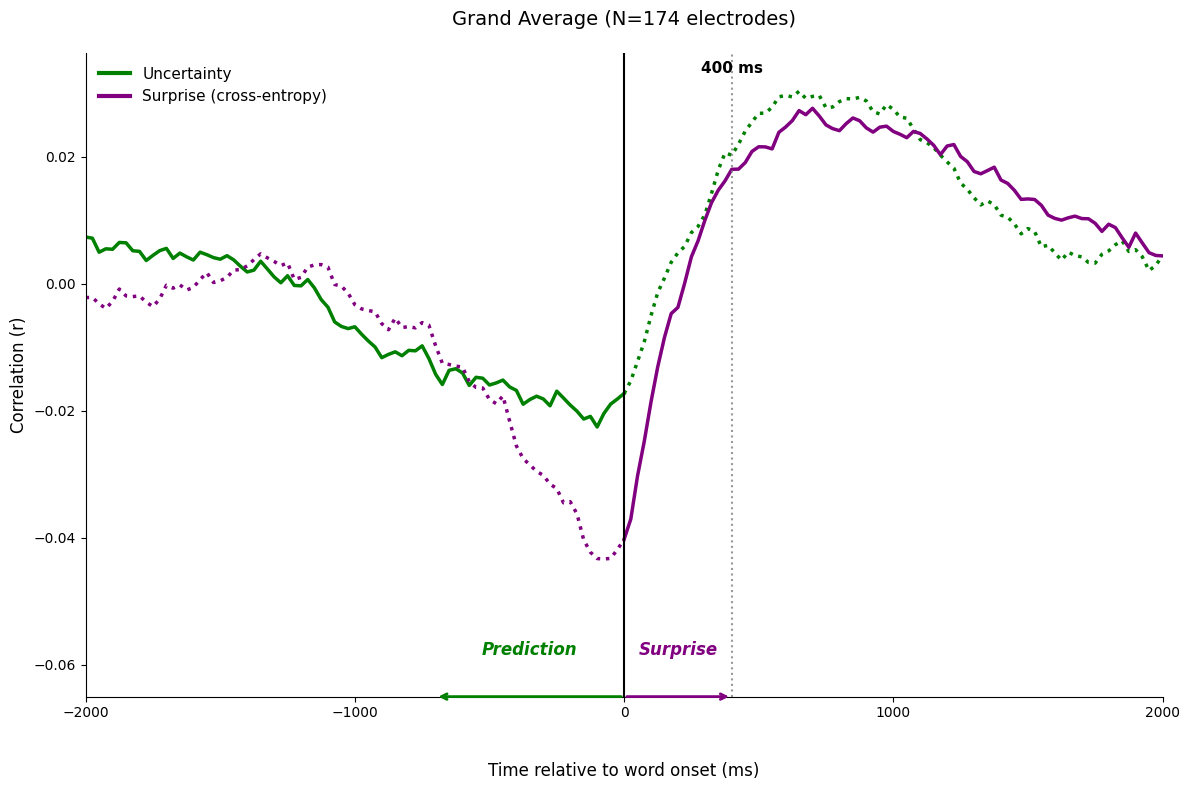

In [38]:
########### Plotting regular Correlations

ent_arr = np.array(all_entropy_rs)
surp_arr = np.array(all_surprise_rs)

# Convert lags to milliseconds
lags_ms = lags * 1000
zero_idx = np.argmin(np.abs(lags_ms))

# Calculate Grand Average
m_ent_all = ent_arr.mean(axis=0)
m_surp_all = surp_arr.mean(axis=0)

# Define legend handles
custom_lines = [
    Line2D([0], [0], color='green', lw=3),
    Line2D([0], [0], color='purple', lw=3)
]

def plot_publication_style_replica(ent_data, surp_data, title, n_elecs):
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # 1. Plot Curves (Solid/Dotted split)
    ax.plot(lags_ms[:zero_idx+1], ent_data[:zero_idx+1], color='green', lw=2.5, linestyle='-', label='Uncertainty')
    ax.plot(lags_ms[zero_idx:], ent_data[zero_idx:], color='green', lw=2.5, linestyle=':')
    
    ax.plot(lags_ms[:zero_idx+1], surp_data[:zero_idx+1], color='purple', lw=2.5, linestyle=':')
    ax.plot(lags_ms[zero_idx:], surp_data[zero_idx:], color='purple', lw=2.5, linestyle='-', label='Surprise')

    # 2. Set Axis Limits & Dynamic Floor
    data_min = min(ent_data.min(), surp_data.min())
    data_max = max(ent_data.max(), surp_data.max())
    
    y_min = data_min - (abs(data_min) * 0.5) if data_min < 0 else -0.05
    y_max = data_max + (abs(data_max) * 0.2)
    ax.set_ylim(y_min, y_max)
    ax.set_xlim(-2000, 2000)

    # 3. Vertical Markers
    ax.axvline(0, color="black", lw=1.5)
    ax.axvline(400, color="grey", lw=1.5, ls=":", alpha=0.8)
    ax.text(400, y_max * 0.9, "400 ms", ha='center', va='bottom', 
            fontsize=11, color='black', fontweight='bold')

    # 4. Styling Spines
    ax.spines['bottom'].set_position(('data', y_min))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # 5. Arrows on the Floor
    ax.annotate('', xy=(-700, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='green', lw=2))
    ax.text(-350, y_min + (abs(y_min)*0.1), "Prediction", 
            color="green", style="italic", ha="center", fontweight='bold', fontsize=12)

    ax.annotate('', xy=(400, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='purple', lw=2))
    ax.text(200, y_min + (abs(y_min)*0.1), "Surprise", 
            color="purple", style="italic", ha="center", fontweight='bold', fontsize=12)

    # 6. Final Formatting
    ax.set_xticks([-2000, -1000, 0, 1000, 2000])
    ax.set_xlabel("Time relative to word onset (ms)", fontsize=12, labelpad=30)
    ax.set_ylabel("Correlation (r)", fontsize=12)
    ax.set_title(f"{title} (N={n_elecs} electrodes)", fontsize=14, pad=20)
    
    ax.legend(custom_lines, ['Uncertainty', 'Surprise (cross-entropy)'], 
               loc='upper left', frameon=False, fontsize=11)
    
    plt.tight_layout()
    plt.savefig("PERSON CORR.png", dpi=400, bbox_inches='tight')
    plt.show()

# Plot Grand Average only
plot_publication_style_replica(m_ent_all, m_surp_all, "Grand Average", len(all_entropy_rs))

# Computing Partial Correlation

In [24]:
############## partial correlation with library pingouin####################

# --- 1. SETUP ---
bids_root = "/Users/iadician/Desktop/AI NEURO CODE/"
df = df_gpt_glove.copy()
df['cross_entropy'] = -np.log2(df['true_prob'].clip(lower=1e-10))

sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
tmin, tmax = -2.0, 2.0
lags = np.arange(-2.0, 2.0 + 0.025/2, 0.025) 

all_entropy_rs = []
all_surprise_rs = []

# --- 2. HELPERS ---
def hamming_smooth(data, sfreq, window_ms=50):
    n_samples = int(window_ms / 1000 * sfreq)
    if n_samples % 2 == 0: n_samples += 1
    win = np.hamming(n_samples)
    win /= win.sum()
    smoothed = np.zeros_like(data)
    for ch in range(data.shape[0]):
        fwd = convolve(data[ch], win, mode='same')
        smoothed[ch] = convolve(fwd[::-1], win, mode='same')[::-1]
    return smoothed

def make_events(df_words, sfreq):
    events = np.zeros((len(df_words), 3), dtype=int)
    events[:, 0] = (df_words['start'].values * sfreq).astype(int)
    events[:, 2] = np.arange(len(df_words)) 
    return events

# --- 3. THE SUBJECT LOOP ---
for sid in subject_ids:
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0: continue
    
    print(f"Processing Subject {sid} (Partial Correlation)...")
    
    file_path = BIDSPath(root=f"{bids_root}derivatives/ecogprep", subject=sid, 
                         task="podcast", datatype="ieeg", description="highgamma", 
                         suffix="ieeg", extension=".fif")
    
    try:
        raw = mne.io.read_raw_fif(file_path.fpath, verbose=False, preload=True)
    except: continue
    
    # Selection
    ch2loc = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask = coords_mm[:, 0] < 0
    raw = raw.copy().pick([ch for ch, k in zip(raw.ch_names, lh_mask) if k])
    valid_indices = [i for i in sub_sig["elec_idx"].values if i < len(raw.ch_names)]
    raw = raw.copy().pick([raw.ch_names[i] for i in valid_indices])
    
    sfreq = raw.info['sfreq']
    data = zscore(np.log10(np.clip(raw.get_data(), 1e-10, None)), axis=1)
    data = hamming_smooth(data, sfreq, 50)
    raw_proc = mne.io.RawArray(data, raw.info, verbose=False)
    
    epochs = mne.Epochs(raw_proc, make_events(df, sfreq), tmin=tmin, tmax=tmax, 
                        baseline=None, preload=True, verbose=False, event_repeated='merge')
    
    df_filtered = df.iloc[epochs.selection]
    # We don't necessarily need to Z-score features for Pingouin, but it helps keep R-values comparable
    ent_feat = zscore(df_filtered['entropy'].values)
    surp_feat = zscore(df_filtered['cross_entropy'].values)
    
    epochs_data = epochs.get_data(copy=True)
    lag_indices = [np.argmin(np.abs(epochs.times - τ)) for τ in lags]
    binned_data = epochs_data[:, :, lag_indices]

    # --- PARTIAL CORRELATION LOOP ---
    n_words, n_elecs, n_lags = binned_data.shape
    for e in range(n_elecs):
        e_ent, e_surp = [], []
        for t in range(n_lags):
            brain_vec = binned_data[:, e, t]
            
            # Create a temporary dataframe for Pingouin
            temp_df = pd.DataFrame({
                'brain': brain_vec,
                'entropy': ent_feat,
                'surprise': surp_feat
            })
            
            # 1. Brain vs Entropy (Controlling for Surprise)
            r_ent = pg.partial_corr(data=temp_df, x='brain', y='entropy', covar='surprise')['r'].values[0]
            # 2. Brain vs Surprise (Controlling for Entropy)
            r_surp = pg.partial_corr(data=temp_df, x='brain', y='surprise', covar='entropy')['r'].values[0]
            
            e_ent.append(r_ent)
            e_surp.append(r_surp)
        
        all_entropy_rs.append(e_ent)
        all_surprise_rs.append(e_surp)



Processing Subject 03 (Partial Correlation)...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/700898139.py:62: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, make_events(df, sfreq), tmin=tmin, tmax=tmax,


Processing Subject 04 (Partial Correlation)...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/700898139.py:62: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, make_events(df, sfreq), tmin=tmin, tmax=tmax,


Processing Subject 05 (Partial Correlation)...


...

/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/700898139.py:62: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, make_events(df, sfreq), tmin=tmin, tmax=tmax,


Processing Subject 08 (Partial Correlation)...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/700898139.py:62: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, make_events(df, sfreq), tmin=tmin, tmax=tmax,


Processing Subject 09 (Partial Correlation)...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_71042/700898139.py:62: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw_proc, make_events(df, sfreq), tmin=tmin, tmax=tmax,


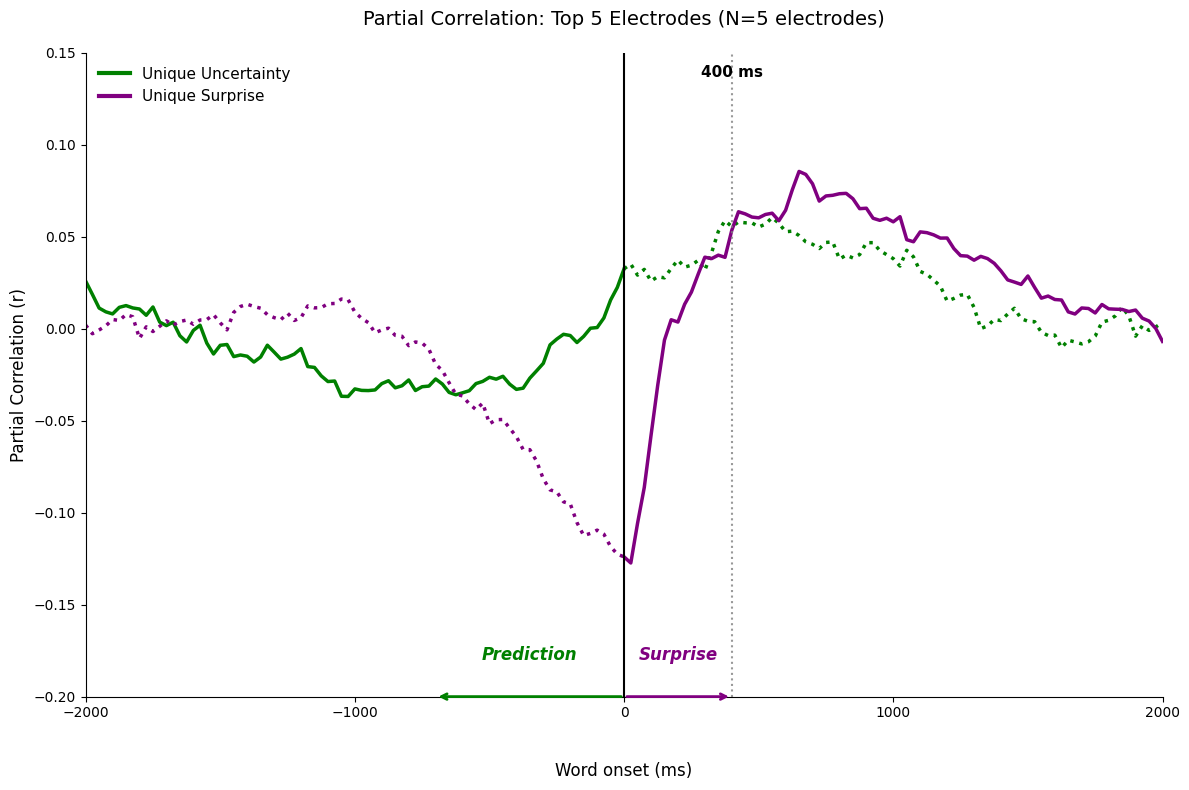

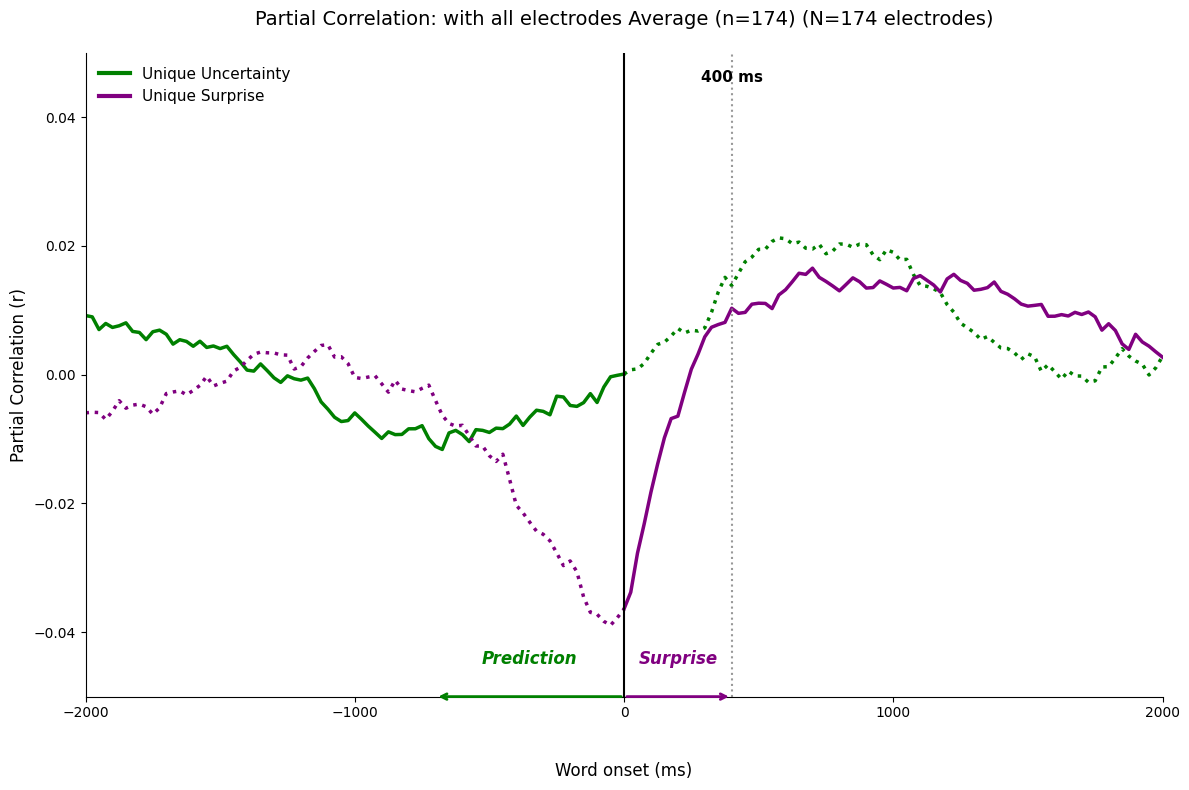

In [25]:
#PLOTTING #############################


# --- 4. DATA PREP FOR PLOTTING ---
ent_arr, surp_arr = np.array(all_entropy_rs), np.array(all_surprise_rs)

# Top 5 Filter
peak_scores = np.max(np.abs(surp_arr), axis=1)
top_5_idx = np.argsort(peak_scores)[-5:]

m_ent_top5 = ent_arr[top_5_idx].mean(axis=0)
m_surp_top5 = surp_arr[top_5_idx].mean(axis=0)

m_ent_all = ent_arr.mean(axis=0)
m_surp_all = surp_arr.mean(axis=0)

custom_lines = [Line2D([0], [0], color='green', lw=3), Line2D([0], [0], color='purple', lw=3)]

# --- 5. REPLICATED PLOTTING FUNCTION ---
def plot_publication_style_replica(ent_data, surp_data, title, n_elecs, y_min_val, y_max_val):
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Curves (Solid/Dotted split)
    ax.plot(lags_ms[:zero_idx+1], ent_data[:zero_idx+1], color='green', lw=2.5, linestyle='-')
    ax.plot(lags_ms[zero_idx:], ent_data[zero_idx:], color='green', lw=2.5, linestyle=':')
    ax.plot(lags_ms[:zero_idx+1], surp_data[:zero_idx+1], color='purple', lw=2.5, linestyle=':')
    ax.plot(lags_ms[zero_idx:], surp_data[zero_idx:], color='purple', lw=2.5, linestyle='-')

    ax.set_ylim(y_min_val, y_max_val)
    ax.set_xlim(-2000, 2000)

    # Vertical Markers
    ax.axvline(0, color="black", lw=1.5) 
    ax.axvline(400, color="grey", lw=1.5, ls=":", alpha=0.8) 
    ax.text(400, y_max_val * 0.9, "400 ms", ha='center', va='bottom', fontsize=11, color='black', fontweight='bold')

    # Floor Style
    ax.spines['bottom'].set_position(('data', y_min_val))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Arrows on Floor
    ax.annotate('', xy=(-700, y_min_val), xytext=(0, y_min_val), arrowprops=dict(arrowstyle='->', color='green', lw=2))
    ax.text(-350, y_min_val + (abs(y_min_val)*0.1), "Prediction", color="green", style="italic", ha="center", fontweight='bold', fontsize=12)

    ax.annotate('', xy=(400, y_min_val), xytext=(0, y_min_val), arrowprops=dict(arrowstyle='->', color='purple', lw=2))
    ax.text(200, y_min_val + (abs(y_min_val)*0.1), "Surprise", color="purple", style="italic", ha="center", fontweight='bold', fontsize=12)

    ax.set_xticks([-2000, -1000, 0, 1000, 2000])
    ax.set_xlabel("Word onset (ms)", fontsize=12, labelpad=30)
    ax.set_ylabel("Partial Correlation (r)", fontsize=12)
    ax.set_title(f"{title} (N={n_elecs} electrodes)", fontsize=14, pad=20)
    ax.legend(custom_lines, ['Unique Uncertainty', 'Unique Surprise'], loc='upper left', frameon=False, fontsize=11)
    
    plt.tight_layout()
    plt.show()

# --- 6. EXECUTE PLOTS ---
# Plot 1: Top 5 - floor at -0.10
plot_publication_style_replica(m_ent_top5, m_surp_top5, "Partial Correlation: Top 5 Electrodes", 5, -0.20, 0.15)

# Plot 2: Grand Average - floor at -0.05
plot_publication_style_replica(m_ent_all, m_surp_all, "Partial Correlation: with all electrodes Average (n=174)", len(all_entropy_rs), -0.05, 0.05)

Running significance testing across all electrodes...


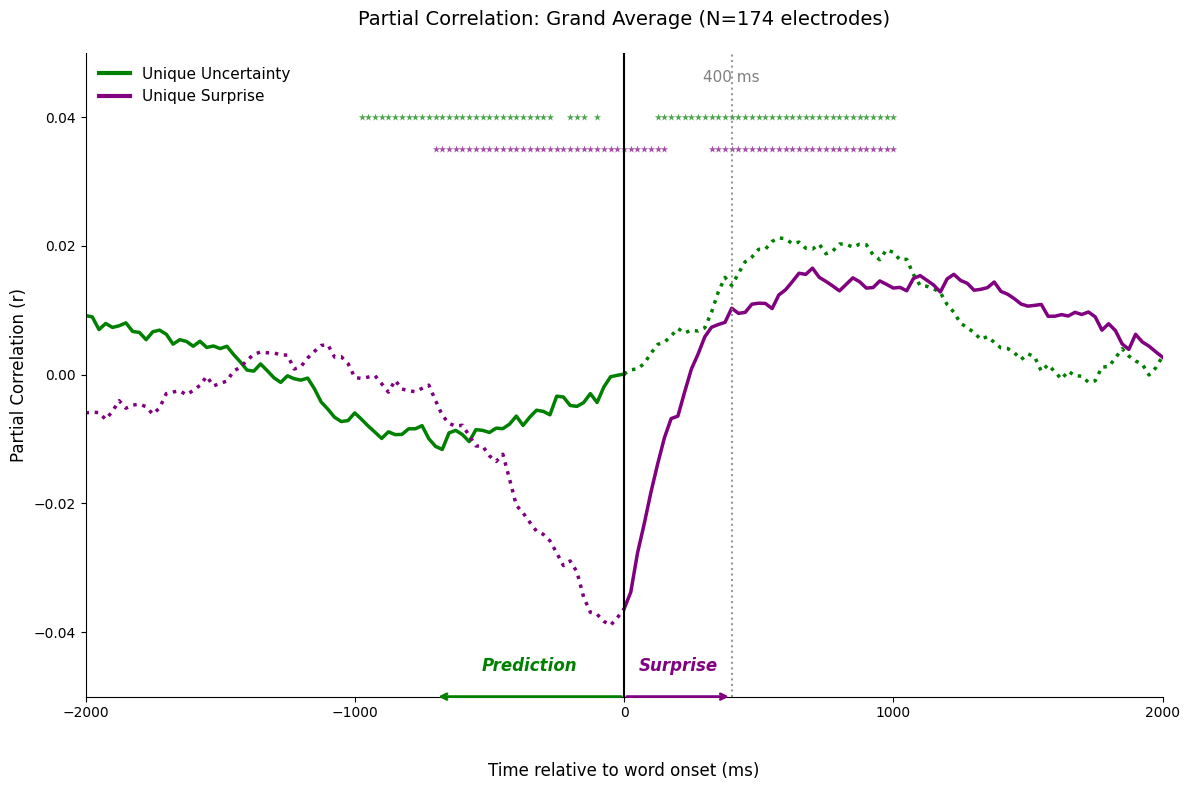

In [30]:
############### SIGNIFICANCE TESTING & ASTERISKS ####################

from scipy.stats import ttest_1samp

# --- 1. DATA PREP ---
ent_arr = np.array(all_entropy_rs)
surp_arr = np.array(all_surprise_rs)

m_ent_all = ent_arr.mean(axis=0)
m_surp_all = surp_arr.mean(axis=0)

lags_ms = lags * 1000
zero_idx = np.argmin(np.abs(lags_ms))

# --- 2. SIGNIFICANCE TESTING ---
print("Running significance testing across all electrodes...")
_, p_vals_ent = ttest_1samp(ent_arr, 0, axis=0)
_, p_vals_surp = ttest_1samp(surp_arr, 0, axis=0)

sig_ent, _ = fdrcorrection(p_vals_ent, alpha=0.01)
sig_surp, _ = fdrcorrection(p_vals_surp, alpha=0.01)

# --- NEW: TIME WINDOW FILTER FOR ASTERISKS ---
# Create a mask that is True only between -1000 and +1000 ms
time_mask = (lags_ms >= -1000) & (lags_ms <= 1000)

# Filter the significance arrays using the time mask
sig_ent_filtered = sig_ent & time_mask
sig_surp_filtered = sig_surp & time_mask

# --- 3. PLOTTING GRAND AVERAGE ---
y_min, y_max = -0.05, 0.05
fig, ax = plt.subplots(figsize=(12, 8))

# A. Curves
ax.plot(lags_ms[:zero_idx+1], m_ent_all[:zero_idx+1], color='green', lw=2.5, linestyle='-')
ax.plot(lags_ms[zero_idx:], m_ent_all[zero_idx:], color='green', lw=2.5, linestyle=':')

ax.plot(lags_ms[:zero_idx+1], m_surp_all[:zero_idx+1], color='purple', lw=2.5, linestyle=':')
ax.plot(lags_ms[zero_idx:], m_surp_all[zero_idx:], color='purple', lw=2.5, linestyle='-')

# B. Significance Markers (Asterisks restricted to -1000 to 1000)
star_y = y_max * 0.8
if sig_ent_filtered.any():
    ax.scatter(lags_ms[sig_ent_filtered], np.full(sig_ent_filtered.sum(), star_y),
               marker="*", s=30, color="green", linewidths=0, alpha=0.7)
if sig_surp_filtered.any():
    # Offset slightly down if both are significant
    ax.scatter(lags_ms[sig_surp_filtered], np.full(sig_surp_filtered.sum(), star_y - 0.005),
               marker="*", s=30, color="purple", linewidths=0, alpha=0.7)

# C. Vertical Markers & Labels
ax.axvline(0, color="black", lw=1.5) 
ax.axvline(400, color="grey", lw=1.5, ls=":", alpha=0.8) 
ax.text(400, star_y + 0.005, "400 ms", ha='center', va='bottom', 
        fontsize=11, color='grey', fontweight='normal')

# D. Floor Styling
ax.set_ylim(y_min, y_max)
ax.set_xlim(-2000, 2000)
ax.spines['bottom'].set_position(('data', y_min))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# E. Arrows on the Floor
ax.annotate('', xy=(-700, y_min), xytext=(0, y_min),
            arrowprops=dict(arrowstyle='->', color='green', lw=2))
ax.text(-350, y_min + 0.004, "Prediction", color="green", 
        style="italic", ha="center", fontweight='bold', fontsize=12)

ax.annotate('', xy=(400, y_min), xytext=(0, y_min),
            arrowprops=dict(arrowstyle='->', color='purple', lw=2))
ax.text(200, y_min + 0.004, "Surprise", color="purple", 
        style="italic", ha="center", fontweight='bold', fontsize=12)

# F. Final Formatting
ax.set_xticks([-2000, -1000, 0, 1000, 2000])
ax.set_xlabel("Time relative to word onset (ms)", fontsize=12, labelpad=30)
ax.set_ylabel("Partial Correlation (r)", fontsize=12)
ax.set_title(f"Partial Correlation: Grand Average (N={len(all_entropy_rs)} electrodes)", fontsize=14, pad=20)

custom_lines = [Line2D([0], [0], color='green', lw=3), Line2D([0], [0], color='purple', lw=3)]
ax.legend(custom_lines, ['Unique Uncertainty', 'Unique Surprise'], 
           loc='upper left', frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig("FIGGGG.png", dpi=400, bbox_inches='tight')
plt.show()